In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#  LU solver (from the class notebook)

def forward_sub(L, b):
    """Solve L x = b for lower-triangular L."""
    n = L.shape[0]
    x = np.zeros(n)
    for i in range(n):
        tmp = b[i]
        for j in range(i):
            tmp -= L[i, j] * x[j]
        x[i] = tmp / L[i, i]
    return x

def back_sub(U, b):
    """Solve U x = b for upper-triangular U."""
    n = U.shape[0]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        tmp = b[i]
        for j in range(i + 1, n):
            tmp -= U[i, j] * x[j]
        x[i] = tmp / U[i, i]
    return x

def lu_decomp(A):
    """ A = L U (no pivoting)."""
    N = A.shape[0]
    L = np.eye(N)
    U = A.copy()
    for c in range(N):
        for r in range(c + 1, N):
            if U[c, c] == 0:
                raise ZeroDivisionError("Zero pivot encountered.")
            factor = U[r, c] / U[c, c]
            L[r, c] = factor
            U[r, :] -= factor * U[c, :]
    return L, U

def linear_solve_without_pivoting(A, b):
    L, U = lu_decomp(A)
    return back_sub(U, forward_sub(L, b))

In [ ]:
# Building  A  and  b  and solving
def build_system(n, a=0.0, b_end=np.pi/2):
    """Return x, A, b for the finite-difference system with n divisions."""
    h = (b_end - a) / n
    x = np.linspace(a, b_end, n + 1)      # x_1, ..., x_{n+1}
    N = n + 1                             # number of unknowns
    A = np.zeros((N, N))
    b = np.zeros(N)

    # Row 1: Dirichlet condition y(0) = 0
    A[0, 0] = 1.0
    b[0] = 0.0

    # Interior rows: y_{i-1} + (-2+4h^2) y_i + y_{i+1} = 4 h^2 x_i
    for i in range(1, N - 1):
        A[i, i - 1] = 1.0
        A[i, i]     = -2.0 + 4.0 * h**2
        A[i, i + 1] = 1.0
        b[i] = 4.0 * h**2 * x[i]

    # Last row: Neumann condition y'(pi/2) = 0 via ghost node y_{n+2} = y_n
    A[-1, -2] = 2.0
    A[-1, -1] = -2.0 + 4.0 * h**2
    b[-1] = 4.0 * h**2 * x[-1]
    return x, A, b

def solve_bvp(n):
    x, A, b = build_system(n)
    y = linear_solve_without_pivoting(A, b)
    # sanity check against NumPy's solver
    assert np.allclose(y, np.linalg.solve(A, b))
    return x, y

In [ ]:
np.set_printoptions(precision=4, suppress=True, linewidth=150)
x10, A10, b10 = build_system(10)
print("h =", (np.pi/2)/10)
print("A =\n", A10)
print("b =\n", b10)

h = 0.15707963267948966
A =
 [[ 1.      0.      0.      0.      0.      0.      0.      0.      0.      0.      0.    ]
 [ 1.     -1.9013  1.      0.      0.      0.      0.      0.      0.      0.      0.    ]
 [ 0.      1.     -1.9013  1.      0.      0.      0.      0.      0.      0.      0.    ]
 [ 0.      0.      1.     -1.9013  1.      0.      0.      0.      0.      0.      0.    ]
 [ 0.      0.      0.      1.     -1.9013  1.      0.      0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      1.     -1.9013  1.      0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      0.      1.     -1.9013  1.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      0.      0.      1.     -1.9013  1.      0.      0.    ]
 [ 0.      0.      0.      0.      0.      0.      0.      1.     -1.9013  1.      0.    ]
 [ 0.      0.      0.      0.      0.      0.      0.      0.      1.     -1.9013  1.    ]
 [ 0.      0.      0.      0.      0.      0.      0.      0.

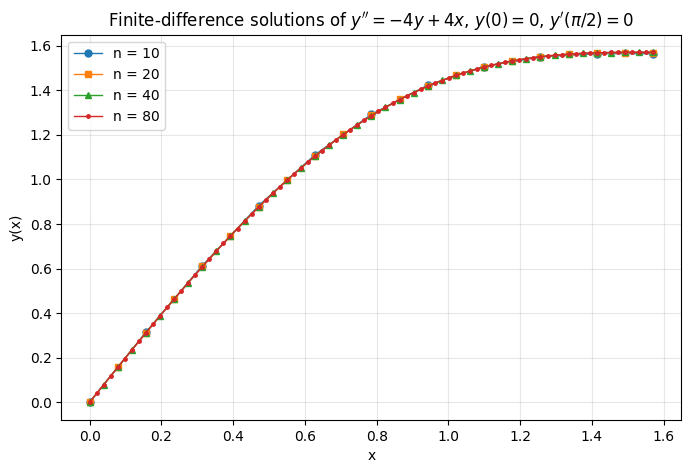

In [ ]:
# Building  A  and  b  and solving
ns = [10, 20, 40, 80]
sols = {n: solve_bvp(n) for n in ns}

plt.figure(figsize=(8, 5))
markers = {10: 'o', 20: 's', 40: '^', 80: '.'}
for n in ns:
    x, y = sols[n]
    plt.plot(x, y, marker=markers[n], ms=5, lw=1, label=f'n = {n}')
plt.xlabel('x'); plt.ylabel('y(x)')
plt.title(r"Finite-difference solutions of $y''=-4y+4x$, $y(0)=0$, $y'(\pi/2)=0$")
plt.grid(alpha=0.3); plt.legend()
plt.show()

In [ ]:
print(f"{'n':>4} {'h':>10} {'y(pi/4)':>12} {'y(pi/2)':>12}")
for n in ns:
    x, y = sols[n]
    print(f"{n:>4} {np.pi/2/n:>10.5f} {y[n//2]:>12.6f} {y[-1]:>12.6f}")

   n          h      y(pi/4)      y(pi/2)
  10    0.15708     1.291716     1.564181
  20    0.07854     1.286949     1.569172
  40    0.03927     1.285784     1.570392
  80    0.01963     1.285495     1.570695


### Observations

* All the curves have the same shape and lie almost on top of each other. Refining the grid makes only small changes, so the numerical solution is converging as n increases.
* The differences between successive grids shrink by 4 roughly each time n doubles which follows the difference formulas which have a h^2 truncation error.
* n=10 is already a good approximation since its values differ from the n=80 values by less than 0.01.

## Extra Credit: Exact solution

The ODE $y'' + 4y = 4x$ is linear with constant coefficients.

* Homogeneous solution: $r^2 + 4 = 0 \Rightarrow r = \pm 2i$, so $y_h = C_1\cos 2x + C_2\sin 2x$.
* Particular solution: try $y_p = ax + b$. Then $0 + 4(ax+b) = 4x \Rightarrow a=1,\ b=0$, so $y_p = x$.

General solution: $y = C_1\cos 2x + C_2 \sin 2x + x$.

* $y(0) = 0 \Rightarrow C_1 = 0$.
* $y'(x) = 2C_2\cos 2x + 1$, and $y'(\pi/2) = 2C_2\cos\pi + 1 = -2C_2 + 1 = 0 \Rightarrow C_2 = \tfrac12$.

$${\,y(x) = x + \tfrac12 \sin 2x\,}$$

Check: $y'' = -2\sin 2x$ and $-4y + 4x = -4x - 2\sin 2x + 4x = -2\sin 2x$. ✓

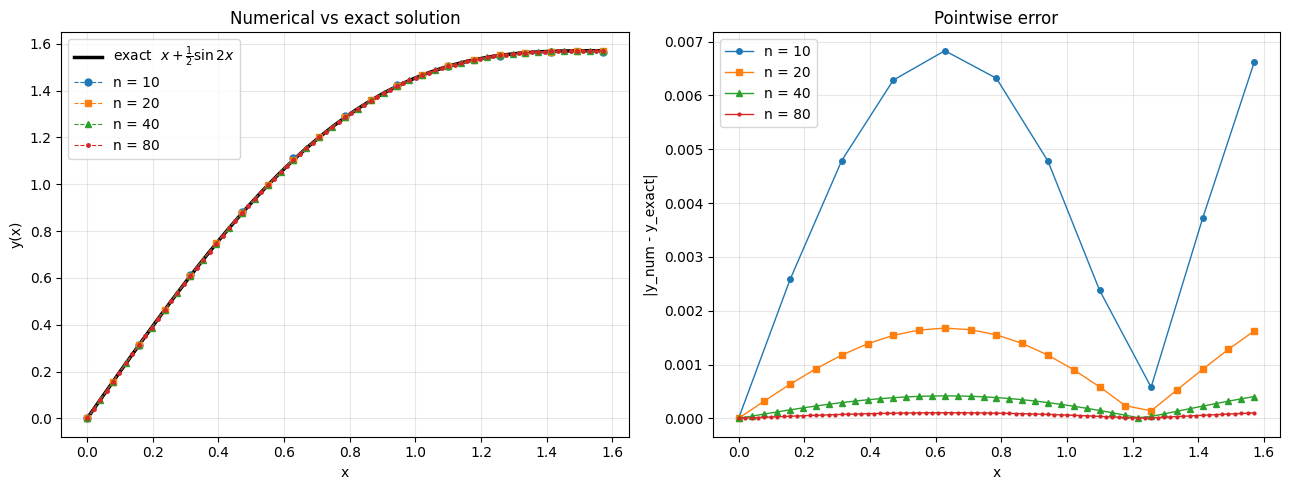

In [ ]:
def y_exact(x):
    return x + 0.5 * np.sin(2 * x)

xf = np.linspace(0, np.pi/2, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].plot(xf, y_exact(xf), 'k-', lw=2.5, label='exact  $x+\\frac{1}{2}\\sin 2x$')
for n in ns:
    x, y = sols[n]
    ax[0].plot(x, y, marker=markers[n], ms=5, lw=0.8, ls='--', label=f'n = {n}')
ax[0].set_xlabel('x'); ax[0].set_ylabel('y(x)')
ax[0].set_title('Numerical vs exact solution'); ax[0].grid(alpha=0.3); ax[0].legend()

for n in ns:
    x, y = sols[n]
    ax[1].plot(x, np.abs(y - y_exact(x)), marker=markers[n], ms=4, lw=1, label=f'n = {n}')
ax[1].set_xlabel('x'); ax[1].set_ylabel('|y_num - y_exact|')
ax[1].set_title('Pointwise error'); ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout(); plt.show()

   n          h    max error    ratio  observed order
  10    0.15708    6.830e-03
  20    0.07854    1.676e-03     4.07            2.03
  40    0.03927    4.172e-04     4.02            2.01
  80    0.01963    1.042e-04     4.00            2.00


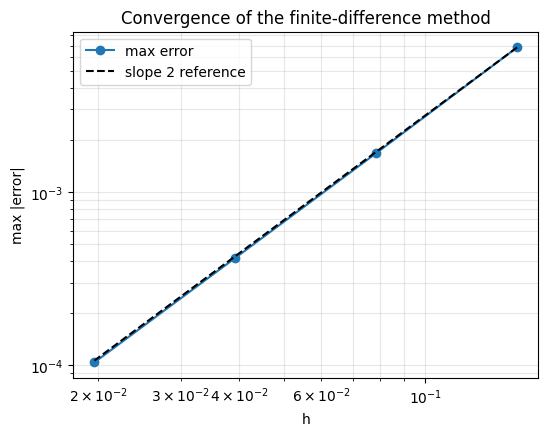

In [ ]:
print(f"{'n':>4} {'h':>10} {'max error':>12} {'ratio':>8} {'observed order':>15}")
prev = None
errs = []
for n in ns:
    x, y = sols[n]
    e = np.max(np.abs(y - y_exact(x)))
    errs.append(e)
    if prev is None:
        print(f"{n:>4} {np.pi/2/n:>10.5f} {e:>12.3e}")
    else:
        print(f"{n:>4} {np.pi/2/n:>10.5f} {e:>12.3e} {prev/e:>8.2f} {np.log2(prev/e):>15.2f}")
    prev = e

hs = np.array([np.pi/2/n for n in ns])
plt.figure(figsize=(6, 4.5))
plt.loglog(hs, errs, 'o-', label='max error')
plt.loglog(hs, errs[0]*(hs/hs[0])**2, 'k--', label='slope 2 reference')
plt.xlabel('h'); plt.ylabel('max |error|'); plt.title('Convergence of the finite-difference method')
plt.grid(which='both', alpha=0.3); plt.legend(); plt.show()

### Comparison with the exact solution

* The numerical solutions agree closely with y(x) = x + 1/2sin 2x for every n, and improves as n increases.
* Each time n is doubled h is halved, the maximum error drops by a factor of about 4. The observed order is about 2 and on the log–log plot the error follows the slope-2 line. This confirms the second-order accuracy predicted by the Taylor-series error terms $-\tfrac{h^2}{6}f'''$ and $-\tfrac{h^2}{12}f^{(iv)}$ from the lecture.
* For n=80 the maximum error is on the order of 10^-4, which makes the curve essentially the same from the exact solution on the plot.